### paper link: https://www.science.org/doi/10.1126/sciadv.adj5778?referrer=https%3A%2F%2Fwww.google.com%2F#
### data raw: https://osf.io/ytf89/files/snuwd

In [1]:
%pip install pandas matplotlib numpy plotly country_converter
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import re
import plotly.express as px
import country_converter as coco

df=pd.read_csv('data_raw.csv',encoding = "ISO-8859-1")
print(df.columns)
raw=df
df.dtypes.value_counts()

Note: you may need to restart the kernel to use updated packages.


/var/folders/84/wvnn9yns4ns67p0snf1b9rcr0000gn/T/ipykernel_11356/152037044.py:9: DtypeWarning: Columns (0: WEPTdemo1_1, 1: WEPTdemo2_1, 2: WEPT1nums_3, 3: WEPT2nums_1, 4: WEPT3nums_1, 5: WEPT5nums_1, 6: WEPT5nums_2, 7: WEPT5nums_4, 8: WEPT6nums_1, 9: WEPT6nums_2, 10: WEPT6nums_4, 11: WEPT7nums_1, 12: WEPT7nums_4, 13: WEPT8nums_1, 14: WEPT8nums_2, 15: WEPT8nums_4, 16: Attn_60, 17: Gender_4_TEXT, 18: Gender_DO, 19: ParticipantType, 20: ui, 21: u) have mixed types. Specify dtype option on import or set low_memory=False.
  df=pd.read_csv('data_raw.csv',encoding = "ISO-8859-1")


Index(['StartDate', 'EndDate', 'Status', 'Progress', 'Duration..in.seconds.',
       'Finished', 'RecordedDate', 'ResponseId', 'DistributionChannel',
       'UserLanguage',
       ...
       'ui', 'u', 'cond', 'condName', 'FL_49_DO', 'FL_17_DO', 'FL_32_DO',
       'X1.ControlConditionIV.termsprobing_DO', 'country', 'AttentionCheck60'],
      dtype='str', length=667)


float64    575
str         76
object      16
Name: count, dtype: int64

# drop nan and duplicate

In [2]:
df.isna().sum()

StartDate                                  342
EndDate                                    342
Status                                     342
Progress                                   342
Duration..in.seconds.                      342
                                         ...  
FL_17_DO                                  9435
FL_32_DO                                 78511
X1.ControlConditionIV.termsprobing_DO    78561
country                                      0
AttentionCheck60                          4950
Length: 667, dtype: int64

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 83927 entries, 0 to 83926
Columns: 667 entries, StartDate to AttentionCheck60
dtypes: float64(575), object(16), str(76)
memory usage: 464.4+ MB


In [4]:
df.duplicated().sum()

np.int64(326)

In [5]:
df=df.drop_duplicates()
df.info()
df=df.dropna(subset=['AttentionCheck60','AttentionCheck_purp','Attn_60','Finished','ResponseId'])
df.info()
df.isna().sum()

<class 'pandas.DataFrame'>
Index: 83601 entries, 0 to 83926
Columns: 667 entries, StartDate to AttentionCheck60
dtypes: float64(575), object(16), str(76)
memory usage: 463.4+ MB
<class 'pandas.DataFrame'>
Index: 61540 entries, 0 to 83926
Columns: 667 entries, StartDate to AttentionCheck60
dtypes: float64(575), object(16), str(76)
memory usage: 345.6+ MB


StartDate                                    0
EndDate                                      0
Status                                       0
Progress                                     0
Duration..in.seconds.                        0
                                         ...  
FL_17_DO                                   475
FL_32_DO                                 56395
X1.ControlConditionIV.termsprobing_DO    56428
country                                      0
AttentionCheck60                             0
Length: 667, dtype: int64

# remove invalid age

In [6]:
df= df[df['Age'].between(18, 120)]
df= df[df['Age']% 1 == 0]
df.info()

<class 'pandas.DataFrame'>
Index: 58681 entries, 3 to 83926
Columns: 667 entries, StartDate to AttentionCheck60
dtypes: float64(575), object(16), str(76)
memory usage: 329.7+ MB


# change countries name format for future plotting data

In [7]:
df['country'].unique()

<ArrowStringArray>
[             'usa_3',            'algeria',            'armenia',
          'australia',            'austria',          'belgium_1',
             'brazil',           'bulgaria',           'canada_1',
           'canada_2',              'chile',              'china',
            'czechia',            'denmark',            'ecuador',
            'finland',             'france',             'gambia',
            'germany',              'ghana',             'greece',
              'india',            'ireland',             'israel',
            'italy_1',            'italy_2',            'japan_1',
            'japan_2',              'kenya',             'latvia',
             'mexico',            'morocco',      'netherlands_1',
      'netherlands_2',      'netherlands_3',         'newzealand',
            'nigeria',             'norway',               'peru',
        'philippines',           'poland_1',           'poland_2',
           'portugal',            'romania'

In [8]:
df['country'] = df['country'].str.replace(r'_\d+$', '', regex=True)
df['country'].unique()

<ArrowStringArray>
[               'usa',            'algeria',            'armenia',
          'australia',            'austria',            'belgium',
             'brazil',           'bulgaria',             'canada',
              'chile',              'china',            'czechia',
            'denmark',            'ecuador',            'finland',
             'france',             'gambia',            'germany',
              'ghana',             'greece',              'india',
            'ireland',             'israel',              'italy',
              'japan',              'kenya',             'latvia',
             'mexico',            'morocco',        'netherlands',
         'newzealand',            'nigeria',             'norway',
               'peru',        'philippines',             'poland',
           'portugal',            'romania',             'russia',
        'saudiarabia',             'serbia',          'singapore',
           'slovakia',           'slovenia'

In [9]:
df['country']= df['country'].replace({'southkorea': 'south korea'})
df['country']=coco.convert(names=df['country'], to='ISO3')
df['country'].unique()

<ArrowStringArray>
['USA', 'DZA', 'ARM', 'AUS', 'AUT', 'BEL', 'BRA', 'BGR', 'CAN', 'CHL', 'CHN',
 'CZE', 'DNK', 'ECU', 'FIN', 'FRA', 'GMB', 'DEU', 'GHA', 'GRC', 'IND', 'IRL',
 'ISR', 'ITA', 'JPN', 'KEN', 'LVA', 'MEX', 'MAR', 'NLD', 'NZL', 'NGA', 'NOR',
 'PER', 'PHL', 'POL', 'PRT', 'ROU', 'RUS', 'SAU', 'SRB', 'SGP', 'SVK', 'SVN',
 'ZAF', 'KOR', 'ESP', 'LKA', 'SDN', 'SWE', 'CHE', 'TWN', 'TZA', 'THA', 'TUR',
 'UGA', 'GBR', 'UKR', 'ARE', 'URY', 'VEN', 'VNM']
Length: 62, dtype: str

In [11]:
confirm = [f"WEPT{i}confirm" for i in range(1, 9)]
df[confirm] = df[confirm].replace({1: 1, 2: 0, 7: 0})

# remove unused columns and change time format to pandas date time

In [12]:
df= df.loc[:, ~df.columns.str.endswith((".Click", ".Submit",".Count","_DO"))]
df = df.drop(columns=['ui','u'])
df["StartDate"] = pd.to_datetime(df["StartDate"],format='%d/%m/%Y %H:%M:%S')
df["EndDate"] = pd.to_datetime(df["EndDate"],format='%d/%m/%Y %H:%M:%S')
df.info(verbose=True)

<class 'pandas.DataFrame'>
Index: 58681 entries, 3 to 83926
Data columns (total 173 columns):
 #    Column                  Dtype         
---   ------                  -----         
 0    StartDate               datetime64[us]
 1    EndDate                 datetime64[us]
 2    Status                  float64       
 3    Progress                float64       
 4    Duration..in.seconds.   float64       
 5    Finished                float64       
 6    RecordedDate            str           
 7    ResponseId              str           
 8    DistributionChannel     str           
 9    UserLanguage            str           
 10   Q_RecaptchaScore        float64       
 11   Q5                      float64       
 12   AttentionCheck_purp     float64       
 13   identity_scale1_1       float64       
 14   identity_scale2_1       float64       
 15   Identity_scale3_1       float64       
 16   identity_scale4_1       float64       
 17   identity_scale5_1       float64       
 18   

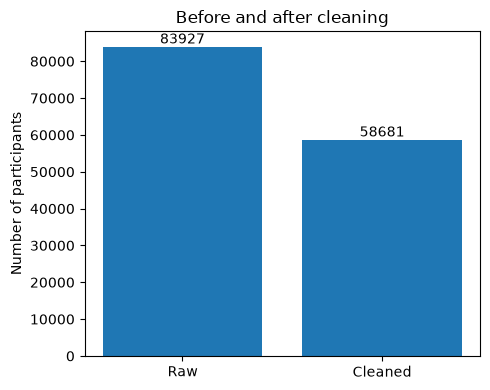

In [13]:
counts = {"Raw": len(raw), "Cleaned": len(df)}

fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(counts.keys(), counts.values())
ax.bar_label(bars)
ax.set_ylabel("Number of participants")
ax.set_title("Before and after cleaning")
plt.tight_layout()
plt.savefig("lmao.svg", format="svg")
plt.show()

# split, normalise data for plotting and removed selected unused rows

In [14]:
policy= df.loc[:, df.columns.str.startswith(("ResponseId","StartDate","EndDate","CC_policy_","country",'MacArthur_SES','Income'))]
policy

,StartDate,EndDate,ResponseId,CC_policy_1,CC_policy_2,CC_policy_3,CC_policy_5,CC_policy_6,CC_policy_7,CC_policy_8,CC_policy_9,CC_policy_10,Income,MacArthur_SES,country
3,2023-02-09 01:55:06,2023-02-09 02:01:32,R_1r7Yr7R1xMimIvj,71.0,97.0,89.0,98.0,90.0,83.0,93.0,81.0,99.0,5.0,7.0,USA
4,2023-02-09 12:33:55,2023-02-09 12:43:25,R_2ATgV5VxewrTRiI,1.0,99.0,99.0,48.0,100.0,99.0,50.0,99.0,1.0,4.0,5.0,USA
5,2023-02-09 12:34:12,2023-02-09 12:43:36,R_3ENlePBlLyYjExr,84.0,82.0,82.0,89.0,85.0,85.0,80.0,85.0,86.0,5.0,8.0,USA
6,2023-02-09 12:35:33,2023-02-09 12:43:53,R_2c0HQgvYzas6mus,1.0,3.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,5.0,4.0,USA
7,2023-02-09 12:33:15,2023-02-09 12:44:23,R_00siryCwgdMus6J,79.0,76.0,73.0,82.0,78.0,91.0,79.0,86.0,78.0,5.0,7.0,USA
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
83919,2022-12-14 07:57:00,2022-12-14 08:14:00,R_3R3p8C0gzLKTcCu,92.0,82.0,85.0,83.0,90.0,92.0,81.0,87.0,86.0,2.0,3.0,VNM
83920,2022-12-14 07:57:00,2022-12-14 08:22:00,R_OeT1JV3yC1aJ4EF,80.0,70.0,70.0,100.0,70.0,100.0,100.0,100.0,60.0,1.0,6.0,VNM
83922,2022-12-14 07:58:00,2022-12-14 08:46:00,R_XAg3G11fkh8J8AN,35.0,99.0,99.0,100.0,36.0,100.0,78.0,100.0,50.0,1.0,10.0,VNM
83925,2022-12-14 08:45:00,2022-12-14 09:15:00,R_2azVf0KXD3rtly8,0.0,100.0,100.0,100.0,0.0,100.0,100.0,100.0,0.0,9.0,7.0,VNM


In [15]:
policy["policy"] = policy.loc[:, policy.columns.str.startswith("CC_policy_")].mean(axis=1)
policy=policy.dropna(subset=["policy","Income", "MacArthur_SES"])
policy
# print(policy[["policy", "Income", "MacArthur_SES"]].corr(method="spearman").round(3))

,StartDate,EndDate,ResponseId,CC_policy_1,CC_policy_2,CC_policy_3,CC_policy_5,CC_policy_6,CC_policy_7,CC_policy_8,CC_policy_9,CC_policy_10,Income,MacArthur_SES,country,policy
3,2023-02-09 01:55:06,2023-02-09 02:01:32,R_1r7Yr7R1xMimIvj,71.0,97.0,89.0,98.0,90.0,83.0,93.0,81.0,99.0,5.0,7.0,USA,89.000000
4,2023-02-09 12:33:55,2023-02-09 12:43:25,R_2ATgV5VxewrTRiI,1.0,99.0,99.0,48.0,100.0,99.0,50.0,99.0,1.0,4.0,5.0,USA,66.222222
5,2023-02-09 12:34:12,2023-02-09 12:43:36,R_3ENlePBlLyYjExr,84.0,82.0,82.0,89.0,85.0,85.0,80.0,85.0,86.0,5.0,8.0,USA,84.222222
6,2023-02-09 12:35:33,2023-02-09 12:43:53,R_2c0HQgvYzas6mus,1.0,3.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,5.0,4.0,USA,1.222222
7,2023-02-09 12:33:15,2023-02-09 12:44:23,R_00siryCwgdMus6J,79.0,76.0,73.0,82.0,78.0,91.0,79.0,86.0,78.0,5.0,7.0,USA,80.222222
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
83919,2022-12-14 07:57:00,2022-12-14 08:14:00,R_3R3p8C0gzLKTcCu,92.0,82.0,85.0,83.0,90.0,92.0,81.0,87.0,86.0,2.0,3.0,VNM,86.444444
83920,2022-12-14 07:57:00,2022-12-14 08:22:00,R_OeT1JV3yC1aJ4EF,80.0,70.0,70.0,100.0,70.0,100.0,100.0,100.0,60.0,1.0,6.0,VNM,83.333333
83922,2022-12-14 07:58:00,2022-12-14 08:46:00,R_XAg3G11fkh8J8AN,35.0,99.0,99.0,100.0,36.0,100.0,78.0,100.0,50.0,1.0,10.0,VNM,77.444444
83925,2022-12-14 08:45:00,2022-12-14 09:15:00,R_2azVf0KXD3rtly8,0.0,100.0,100.0,100.0,0.0,100.0,100.0,100.0,0.0,9.0,7.0,VNM,66.666667


In [16]:
policy["month"] = policy["StartDate"].dt.to_period("M").astype(str)
mean_policy_month = (policy.groupby(["country", "month"])
       .agg(policy=("policy", "mean"), n=("policy", "size"))
       .reset_index())

In [17]:
fig = px.scatter_geo(
    mean_policy_month,
    locations="country",
    color="policy", size="n", hover_name="country",
    animation_frame="month",
    projection="natural earth",
    range_color=(mean_policy_month["policy"].min(), mean_policy_month["policy"].max()),
    title="Average climate policy support by country each month",
)
fig.show()

In [18]:
mean_policy = (policy.groupby("country")
       .agg(policy=("policy", "mean"), n=("policy", "size"))
       .reset_index())

fig = px.scatter_geo(
    mean_policy,
    locations="country",
    color="policy", size="n", hover_name="country",
    projection="natural earth",
    range_color=(mean_policy["policy"].min(), mean_policy["policy"].max()),
    title="Average climate policy support score by country"
)
fig.show()
fig.write_image("mappolicy.svg")

In [19]:
Income_relation = policy.groupby("Income")["policy"].agg(["mean", "sem", "size"]).reset_index()
SES_relation = policy.groupby("MacArthur_SES")["policy"].agg(["mean", "sem", "size"]).reset_index()

fig= px.line(Income_relation, x="Income", y="mean", error_y="sem", markers=True,
        title="Policy support score by income level")
fig.show()
fig.write_image("Income_policy_relation.svg")

fig=px.line(SES_relation, x="MacArthur_SES", y="mean", error_y="sem", markers=True,
        title="Policy support by MacArthur SES status level")
fig.show()
fig.write_image("SES_policy_relation.svg")

heatmap_relation = policy.pivot_table(index="MacArthur_SES", columns="Income", values="policy", aggfunc="mean")

fig=px.imshow(heatmap_relation, origin="lower", aspect="auto", color_continuous_scale="Viridis", text_auto=True,
          labels=dict(x="Income level", y="MacArthur status level", color="Mean policy"),
          title="Policy support mean score by income and MacArthur SES status")
fig.show()
fig.write_image("heatmap.svg")

In [20]:
WEPT_df= df.loc[:, df.columns.str.startswith(("ResponseId","StartDate","EndDate","WEPT","country",'MacArthur_SES'))]
WEPT_df=WEPT_df.dropna(subset=["WEPT1confirm","WEPT2confirm","WEPT3confirm","WEPT4confirm","WEPT5confirm","WEPT6confirm","WEPT7confirm",'WEPT8confirm'],how='all')
WEPT_df

,StartDate,EndDate,ResponseId,WEPTdemo1_1,WEPTdemo2_1,WEPT1confirm,WEPT1nums_1,WEPT1nums_2,WEPT1nums_3,WEPT1nums_4,...,WEPT7nums_6,WEPT8confirm,WEPT8nums_1,WEPT8nums_2,WEPT8nums_3,WEPT8nums_4,WEPT8nums_5,WEPT8nums_6,MacArthur_SES,country
3,2023-02-09 01:55:06,2023-02-09 02:01:32,R_1r7Yr7R1xMimIvj,"3,5","5,7",1.0,"2,6,8,10","7,8",NaN,"4,6,8",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7.0,USA
4,2023-02-09 12:33:55,2023-02-09 12:43:25,R_2ATgV5VxewrTRiI,"3,5","5,7",0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0,USA
5,2023-02-09 12:34:12,2023-02-09 12:43:36,R_3ENlePBlLyYjExr,"3,5","5,7",1.0,"2,6,8,10",7,NaN,"4,8",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8.0,USA
6,2023-02-09 12:35:33,2023-02-09 12:43:53,R_2c0HQgvYzas6mus,"3,5","5,7",0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.0,USA
7,2023-02-09 12:33:15,2023-02-09 12:44:23,R_00siryCwgdMus6J,"3,5","5,7",0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7.0,USA
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
83919,2022-12-14 07:57:00,2022-12-14 08:14:00,R_3R3p8C0gzLKTcCu,"3,5","5,7",0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.0,VNM
83920,2022-12-14 07:57:00,2022-12-14 08:22:00,R_OeT1JV3yC1aJ4EF,"3,5","5,7",1.0,"2,6,8,10","7,8",NaN,"4,6,8",...,5,0.0,NaN,NaN,NaN,NaN,NaN,NaN,6.0,VNM
83922,2022-12-14 07:58:00,2022-12-14 08:46:00,R_XAg3G11fkh8J8AN,"3,5","5,7",1.0,"2,8","7,8",NaN,"4,6,8",...,NaN,1.0,3,"7,9","2,5,6",1,"2,4",5,10.0,VNM
83925,2022-12-14 08:45:00,2022-12-14 09:15:00,R_2azVf0KXD3rtly8,"3,5","5,7",1.0,"2,6,8,10","7,8",NaN,"4,6,8",...,"1,5",1.0,3,"7,9","1,2,5,6,10",1,"3,4","1,5",7.0,VNM


In [21]:
WEPT_df['WEPT7confirm'].unique()

array([nan,  1.,  0.])

In [22]:
confirm = [f"WEPT{i}confirm" for i in range(1, 9)]

WEPT_df["trees"]    = WEPT_df[confirm].sum(axis=1)       # 0 to 8
WEPT_df["any_tree"] = (WEPT_df["trees"] >= 1).astype(int)  # planted at least one
WEPT_df["all8"]     = (WEPT_df["trees"] == 8).astype(int)  # did every page

# the clicked-number and demo columns are not needed for analysis
WEPT_df = WEPT_df.drop(columns=WEPT_df.filter(regex="nums|demo").columns)

print(WEPT_df["trees"].value_counts().sort_index())

trees
0.0    10919
1.0     6322
2.0     5225
3.0     3239
4.0     1379
5.0      663
6.0      298
7.0     1217
8.0    29419
Name: count, dtype: int64


In [ ]:
c = (WEPT_df.groupby("country")
        .agg(trees=("trees", "mean"),
             wept_any=("any_tree", "mean"),
             wept_all8=("all8", "mean"),
             n=("trees", "size"))
        .reset_index())

fig = px.choropleth(c, locations="country", color="trees",
                    hover_name="country",
                    hover_data={"n": True, "wept_any": ":.0%", "wept_all8": ":.0%"},
                    projection="natural earth",
                    title="Mean trees planted in the WEPT by country")
fig.show()
fig.write_image("mapWEPT.svg")

In [24]:
print(c.sort_values('trees'))

   country     trees  wept_any  wept_all8     n
53     TWN  1.127451  0.387255   0.088235   204
23     IND  2.649709  0.603198   0.244186   688
24     IRL  3.003947  0.651316   0.278947   760
1      ARM  3.450704  0.710262   0.315895   497
49     SVN  3.546720  0.763419   0.324056   503
..     ...       ...       ...        ...   ...
39     PHL  5.819444  0.909722   0.625000   144
59     VEN  5.951220  0.902439   0.617886   123
47     SRB  5.970674  0.926686   0.639296   341
9      CHL  6.069196  0.908482   0.680804   448
48     SVK  6.079922  0.878168   0.703704  1026

[62 rows x 5 columns]


In [25]:
print(c.sort_values('n'))

   country     trees  wept_any  wept_all8     n
59     VEN  5.951220  0.902439   0.617886   123
39     PHL  5.819444  0.909722   0.625000   144
54     TZA  3.913706  0.883249   0.360406   197
53     TWN  1.127451  0.387255   0.088235   204
47     SRB  5.970674  0.926686   0.639296   341
..     ...       ...       ...        ...   ...
35     NLD  4.131426  0.809751   0.394277  1887
19     GBR  4.604559  0.808722   0.468285  2018
40     POL  5.549703  0.867460   0.594732  2354
50     SWE  4.137592  0.740377   0.424242  2442
58     USA  4.771106  0.795832   0.510303  8493

[62 rows x 5 columns]


In [ ]:
c = (WEPT_df.groupby("country")
        .agg(wept_all8=("all8", "mean"),
             n=("all8", "size"))
        .reset_index())

fig = px.choropleth(c, locations="country", color="wept_all8",
                    hover_name="country",
                    hover_data={"n": True, "wept_all8": ":.0%"},
                    projection="natural earth",
                    title="Percentage of complete all 8 WEPT tasks by country")
fig.show()
fig.write_image("mapWEPT_all8.svg")